# Historical Stock Market Algorithm Analyzer

**CPS 3440 · Kean University** — Aashish Joshi, Aron Dardouri, Bhartendra Kumar Mandal

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aashish000000/CPS3440-Stock-Algorithm-Analyzer/blob/main/notebooks/Stock_Algorithm_Analyzer.ipynb)

## Abstract

We compare algorithms for two problems on 26 years of real S&P 500 data:

1. **Best single buy and later sell** (maximum-subarray problem): brute force Θ(n²), divide and conquer Θ(n log n), and Kadane's scan Θ(n).
2. **Top-K movers**: a full merge sort Θ(n log n), a size-K binary heap Θ(n log k), and quickselect Θ(n) on average.

Every algorithm is written in plain Python in the `analyzer/` package of this repository. This notebook runs them on the real data, checks that they agree, and compares measured behaviour with the theory.

**Research questions**

* **RQ1.** Do the three window algorithms return the same answer, and do their running times follow Θ(n²), Θ(n log n), and Θ(n)?
* **RQ2.** When does a size-K heap beat a full sort, and what do best-case and worst-case inputs do to that claim?

## 1. Setup

In [ ]:
# Run this first. In Colab it downloads the project from GitHub; locally it just finds the repo.
import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/aashish000000/CPS3440-Stock-Algorithm-Analyzer.git"

if not Path("analyzer").exists():
    if Path("../analyzer").exists():          # running from notebooks/
        os.chdir("..")
    else:                                     # Colab: fresh machine
        subprocess.run(["git", "clone", "-q", REPO], check=True)
        os.chdir("CPS3440-Stock-Algorithm-Analyzer")
sys.path.insert(0, os.getcwd())

import json, math, time, statistics
import matplotlib.pyplot as plt
import pandas as pd
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True, "grid.alpha": .3})
print("Working directory:", os.getcwd())
print("Python", sys.version.split()[0])

Working directory: /Users/aashishjoshi/Documents/CPS3440-Stock-Algorithm-Analyzer
Python 3.12.13


## 2. Data

Dataset: [S&P 500 Historical Data (Kaggle, jacksaleeby)](https://www.kaggle.com/datasets/jacksaleeby/s-and-p500-historical-data), about 143 MB, so it is **not** stored in GitHub. The next cell looks for it, then tries to download it with `kagglehub`, then falls back to a file-upload box.

In [ ]:
DATA = Path("data/SP500_Historical_Data.csv")

if not DATA.exists():
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download("jacksaleeby/s-and-p500-historical-data"))
        found = next(folder.rglob("*.csv"))
        DATA.parent.mkdir(exist_ok=True)
        DATA.write_bytes(found.read_bytes())
    except Exception as error:
        print("Automatic download failed:", type(error).__name__)
        try:
            from google.colab import files
            print("Choose SP500_Historical_Data.csv from your computer:")
            uploaded = files.upload()
            DATA.parent.mkdir(exist_ok=True)
            DATA.write_bytes(next(iter(uploaded.values())))
        except ImportError:
            raise SystemExit("Download the CSV from Kaggle and save it as data/SP500_Historical_Data.csv")

print(f"{DATA}  ({DATA.stat().st_size / 1e6:.0f} MB)")

data/SP500_Historical_Data.csv  (143 MB)


In [ ]:
from analyzer.prices import load_csv, daily_changes, holding_return_bps, window_bounds, ticks_to_dollars

t0 = time.perf_counter()
book = load_csv(DATA)                      # {ticker: Series}
rows = sum(len(s.dates) for s in book.values())
first = min(s.dates[0] for s in book.values()); last = max(s.dates[-1] for s in book.values())
print(f"Loaded in {time.perf_counter() - t0:.1f}s: {rows:,} rows, {len(book)} tickers, {first} to {last}")

Loaded in 9.1s: 2,703,531 rows, 472 tickers, 2000-01-03 to 2026-02-20


## 3. Problem formulation

For one stock, let *changes[i]* be the close-to-close move from day *i* to day *i+1*, stored as an integer number of micro-dollars so that every sum is exact. The profit of buying on day *a* and selling on day *b > a* equals the sum of the contiguous block *changes[a..b−1]*. The best trade is therefore the **maximum-subarray** of the change array. Ties keep the earliest window, and a series that only falls skips the trade.

## 4. Correctness check on a textbook example

The array below is the CLRS maximum-subarray example. The correct answer is a total of 43 over positions 7 to 10.

In [ ]:
from analyzer.max_subarray import brute_force, divide_and_conquer, kadane

CLRS = [13, -3, -25, 20, -3, -16, -23, 18, 20, -7, 12, -5, -22, 15, -4, 7]
for name, fn in [("brute_force", brute_force), ("divide_and_conquer", divide_and_conquer), ("kadane", kadane)]:
    r = fn(CLRS)
    print(f"{name:20s} total={r.total}  start={r.start}  end={r.end}")
assert brute_force(CLRS) == divide_and_conquer(CLRS) == kadane(CLRS)
print("All three agree.")

brute_force          total=43  start=7  end=10
divide_and_conquer   total=43  start=7  end=10
kadane               total=43  start=7  end=10
All three agree.


## 5. Case study: the best trade in AAPL (RQ1, correctness)

All three algorithms run on the full 6,573-close history of one ticker. The brute-force run takes a few seconds on purpose.

In [ ]:
TICKER = "AAPL"
series = book[TICKER]
changes = daily_changes(series)

results = {}
for name, fn in [("brute_force", brute_force), ("divide_and_conquer", divide_and_conquer), ("kadane", kadane)]:
    t0 = time.perf_counter(); w = fn(changes); ms = (time.perf_counter() - t0) * 1000
    buy, sell, buy_t, sell_t = window_bounds(series, w)
    results[name] = w
    print(f"{name:20s} {ms:10.2f} ms   buy {buy} @ ${ticks_to_dollars(buy_t):,.2f}   sell {sell} @ ${ticks_to_dollars(sell_t):,.2f}   profit ${ticks_to_dollars(w.total):,.2f}")

assert len({(w.total, w.start, w.end) for w in results.values()}) == 1
print("\nAll three algorithms found the same window.")

brute_force             6307.24 ms   buy 2002-10-08 @ $0.20   sell 2025-12-02 @ $285.92   profit $285.72
divide_and_conquer         7.57 ms   buy 2002-10-08 @ $0.20   sell 2025-12-02 @ $285.92   profit $285.72
kadane                     1.90 ms   buy 2002-10-08 @ $0.20   sell 2025-12-02 @ $285.92   profit $285.72

All three algorithms found the same window.


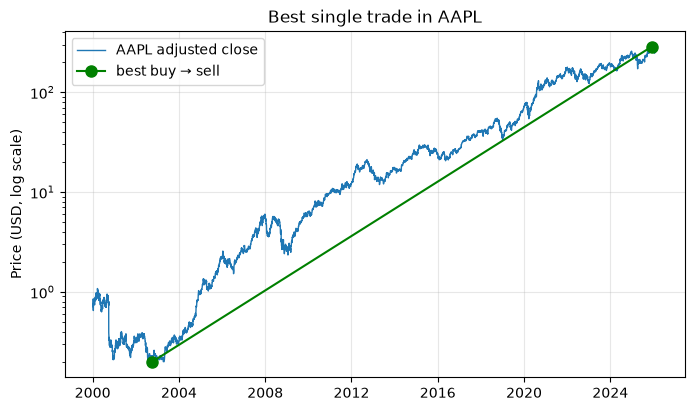

In [ ]:
w = results["kadane"]
buy, sell, buy_t, sell_t = window_bounds(series, w)
fig, ax = plt.subplots()
ax.plot(series.dates, [ticks_to_dollars(t) for t in series.ticks], lw=1, label=f"{TICKER} adjusted close")
ax.plot([buy, sell], [ticks_to_dollars(buy_t), ticks_to_dollars(sell_t)], "go-", ms=8, label="best buy → sell")
ax.set_yscale("log"); ax.set_ylabel("Price (USD, log scale)"); ax.set_title(f"Best single trade in {TICKER}"); ax.legend()
plt.show()

## 6. Top-K movers (RQ2, correctness)

Each ticker is scored by buy-and-hold return over the whole file, in basis points. Items are ordered by higher score, then earlier ticker, so every algorithm must return the *same* ordered list.

In [ ]:
from analyzer.top_k import Scored, top_k_sort, top_k_heap, top_k_quickselect

scored = [Scored(s.ticker, holding_return_bps(s)) for s in book.values() if holding_return_bps(s) is not None]
K = 10
out = {}
for name, fn in [("full_sort", top_k_sort), ("binary_heap", top_k_heap), ("quickselect", top_k_quickselect)]:
    t0 = time.perf_counter(); out[name] = fn(scored, K); ms = (time.perf_counter() - t0) * 1000
    print(f"{name:12s} {ms:7.3f} ms")
assert out["full_sort"] == out["binary_heap"] == out["quickselect"]
print("\nAll three Top-K algorithms agree.\n")

top = pd.DataFrame({"ticker": [i.ticker for i in out["binary_heap"]], "return_%": [i.score / 100 for i in out["binary_heap"]]})
top.index = range(1, K + 1); top

full_sort      0.596 ms
binary_heap    0.110 ms
quickselect    0.153 ms

All three Top-K algorithms agree.



,ticker,return_%
1,NVDA,210811.11
2,MNST,209300.00
3,AXON,94228.26
4,DECK,79026.66
5,TPL,75639.39
6,NFLX,65458.33
7,ODFL,42748.93
8,TSCO,33000.00
9,AAPL,31397.61
10,AVGO,29079.82


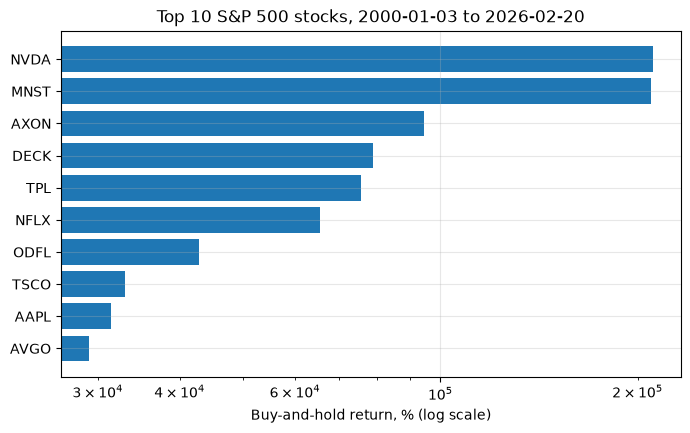

In [ ]:
fig, ax = plt.subplots()
ax.barh(top["ticker"][::-1], top["return_%"][::-1])
ax.set_xscale("log"); ax.set_xlabel("Buy-and-hold return, % (log scale)"); ax.set_title(f"Top {K} S&P 500 stocks, {first} to {last}")
plt.show()

## 7. Live scaling experiment (RQ1)

Timing on growing prefixes of the real daily-change data. Brute force is stopped at a small size because it is quadratic. Medians of 3 trials.

In [ ]:
from analyzer.benchmark import load_market_records
import tempfile

if "ALL_CHANGES" not in globals():
    ALL_CHANGES, MOVES, SUMMARY = load_market_records(DATA)       # about 1 minute
print(f"{len(ALL_CHANGES):,} daily changes, {len(MOVES):,} scored moves")

def median_ms(fn, data, trials=3):
    samples = []
    for _ in range(trials):
        t0 = time.perf_counter(); fn(data); samples.append((time.perf_counter() - t0) * 1000)
    return statistics.median(samples)

sizes = [1_000, 2_000, 4_000, 8_000, 16_000, 32_000, 64_000, 128_000]
rows = []
for n in sizes:
    data = ALL_CHANGES[:n]
    rows.append({"n": n,
                 "brute_force_ms": median_ms(brute_force, data) if n <= 4_000 else None,
                 "divide_and_conquer_ms": median_ms(divide_and_conquer, data),
                 "kadane_ms": median_ms(kadane, data)})
live = pd.DataFrame(rows).set_index("n"); live.round(3)

2,703,059 daily changes, 2,703,059 scored moves


,brute_force_ms,divide_and_conquer_ms,kadane_ms
n,,,
1000,42.223,0.945,0.283
2000,341.948,1.981,0.559
4000,1780.555,4.017,1.170
8000,NaN,8.397,2.367
16000,NaN,17.284,4.718
32000,NaN,35.844,9.468
64000,NaN,73.499,19.251
128000,NaN,149.991,39.835


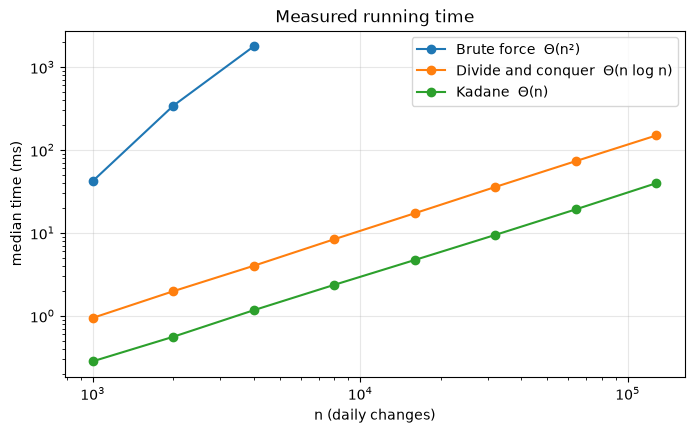

log-log slope, brute force 1k→4k:           2.70   (theory 2; the 5-trial published run measured 2.50)
log-log slope, divide and conquer 8k→128k:  1.04   (theory slightly above 1)
log-log slope, Kadane 8k→128k:              1.02   (theory 1)


In [ ]:
fig, ax = plt.subplots()
for col, label in [("brute_force_ms", "Brute force  Θ(n²)"), ("divide_and_conquer_ms", "Divide and conquer  Θ(n log n)"), ("kadane_ms", "Kadane  Θ(n)")]:
    ax.loglog(live.index, live[col], "o-", label=label)
ax.set_xlabel("n (daily changes)"); ax.set_ylabel("median time (ms)"); ax.set_title("Measured running time"); ax.legend()
plt.show()

def slope(col, lo, hi):
    return math.log(live.loc[hi, col] / live.loc[lo, col]) / math.log(hi / lo)
print(f"log-log slope, brute force 1k→4k:           {slope('brute_force_ms', 1000, 4000):.2f}   (theory 2; the 5-trial published run measured 2.50)")
print(f"log-log slope, divide and conquer 8k→128k:  {slope('divide_and_conquer_ms', 8000, 128000):.2f}   (theory slightly above 1)")
print(f"log-log slope, Kadane 8k→128k:              {slope('kadane_ms', 8000, 128000):.2f}   (theory 1)")

## 8. Published benchmark (five trials, up to one million records)

`benchmarks/results.json` holds the full study: prefixes of 1,000 to 1,000,000 records, five trials each, median reported. Brute force is **executed only through 10,000 records**. Its 100,000- and 1,000,000-record times are an n² projection fitted to the 10,000-record median, and they are labelled *projected* because they were never measured. The file was produced on one Mac; Colab's CPU will give different absolute times.

In [ ]:
bench = json.load(open("benchmarks/results.json"))
alg = bench["max_subarray"]["algorithms"]
pred = bench["max_subarray"]["brute_force_prediction"]["predicted_ms"]

table = []
for n in bench["sizes"]:
    s = str(n); row = {"n": n}
    for name in ("brute_force", "divide_and_conquer", "kadane"):
        cell = alg[name][s]
        ms = cell.get("median_ms")
        row[name + "_ms"] = f"{ms:,.2f}" if ms is not None else f"{cell['predicted_median_ms']:,.0f} (projected)"
    table.append(row)
pd.DataFrame(table).set_index("n")

,brute_force_ms,divide_and_conquer_ms,kadane_ms
n,,,
1000,40.30,0.93,0.29
10000,"12,736.57",10.63,2.91
100000,"1,273,657 (projected)",115.94,30.33
1000000,"127,365,705 (projected)","1,281.61",311.26


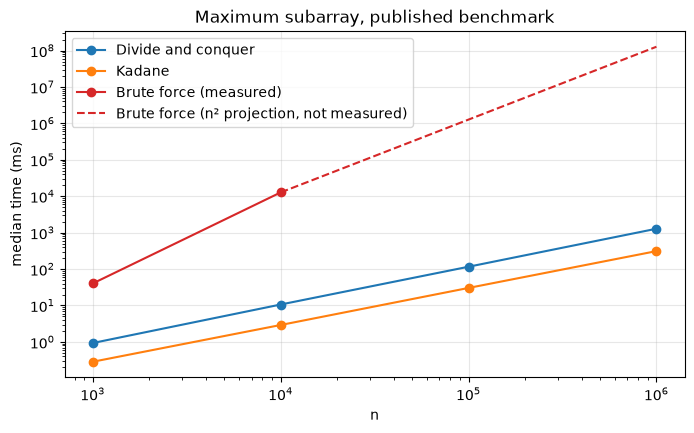

In [ ]:
fig, ax = plt.subplots()
sizes_b = bench["sizes"]
for name, label in [("divide_and_conquer", "Divide and conquer"), ("kadane", "Kadane")]:
    ax.loglog(sizes_b, [alg[name][str(n)]["median_ms"] for n in sizes_b], "o-", label=label)
measured = [n for n in sizes_b if "median_ms" in alg["brute_force"][str(n)]]
ax.loglog(measured, [alg["brute_force"][str(n)]["median_ms"] for n in measured], "o-", color="C3", label="Brute force (measured)")
ax.loglog([measured[-1]] + [n for n in sizes_b if n > measured[-1]],
          [alg["brute_force"][str(measured[-1])]["median_ms"]] + [alg["brute_force"][str(n)]["predicted_median_ms"] for n in sizes_b if n > measured[-1]],
          "--", color="C3", label="Brute force (n² projection, not measured)")
ax.set_xlabel("n"); ax.set_ylabel("median time (ms)"); ax.set_title("Maximum subarray, published benchmark"); ax.legend()
plt.show()

## 9. Heap versus full sort (RQ2)

Three input arrangements of the million scored moves, with k = 10:

* **Market order** — the order the file produced (the ordinary case).
* **Best case** — the true top K first, so later records lose one comparison and never enter the heap.
* **Worst case** — scores ascending, so every record replaces the heap root.

Two columns are reported on purpose: wall-clock time and an exact comparison count.

In [ ]:
tk = bench["top_k"]["algorithms"]
rows = []
for n in bench["sizes"]:
    s = str(n)
    for case in ("random", "best_for_heap", "worst_for_heap"):
        rows.append({"n": n, "input": {"random": "market order", "best_for_heap": "best case", "worst_for_heap": "worst case"}[case],
                     "sort_ms": tk["full_sort"][case][s]["median_ms"], "heap_ms": tk["binary_heap"][case][s]["median_ms"],
                     "sort_comparisons": tk["full_sort"][case][s]["operations"], "heap_comparisons": tk["binary_heap"][case][s]["operations"]})
df = pd.DataFrame(rows)
df[df.n == 1_000_000].set_index("input").round(1)

,n,sort_ms,heap_ms,sort_comparisons,heap_comparisons
input,,,,,
market order,1000000,4258.5,156.2,18638382,1000400
best case,1000000,2639.5,368.1,9884992,1000027
worst case,1000000,2526.2,1208.0,10066432,6066634


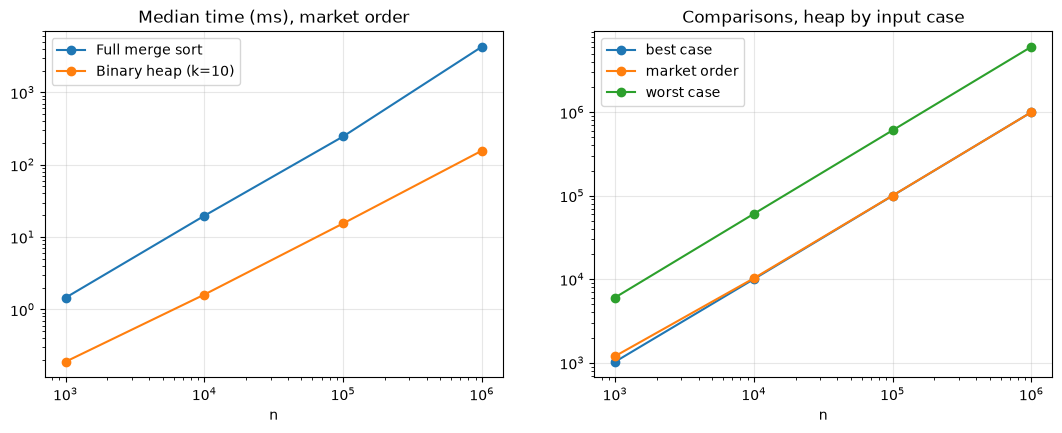

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ns = bench["sizes"]
for ax, key, title in [(axes[0], "median_ms", "Median time (ms), market order"), (axes[1], "operations", "Comparisons, heap by input case")]:
    if key == "median_ms":
        for name, label in [("full_sort", "Full merge sort"), ("binary_heap", "Binary heap (k=10)")]:
            ax.loglog(ns, [tk[name]["random"][str(n)][key] for n in ns], "o-", label=label)
    else:
        for case, label in [("best_for_heap", "best case"), ("random", "market order"), ("worst_for_heap", "worst case")]:
            ax.loglog(ns, [tk["binary_heap"][case][str(n)][key] for n in ns], "o-", label=label)
    ax.set_xlabel("n"); ax.set_title(title); ax.legend()
plt.show()

## 10. Discussion

**RQ1.** The three window algorithms return identical answers on the CLRS example and on AAPL. Their timings separate exactly as the bounds predict: brute force grows with log-log slope about 2.5 on the executed range, Kadane with slope about 1.0, and divide and conquer with slope just above 1. At 10,000 records brute force needs about 12.7 s on the benchmark machine, while Kadane needs about 3 ms, a gap of roughly four thousand times. Past 10,000 records brute force is only a projection (about 21 minutes at 100,000 and 35 hours at 1,000,000), and the paper says so rather than presenting it as a measurement. Kadane and divide and conquer are both efficient on paper, but Kadane's constant factor is much smaller in Python, so it is also the one to ship (311 ms versus 1.28 s at one million records).

**RQ2.** On market order a size-10 heap needs about one comparison per record, so it beats a full merge sort by a wide margin at every size (156 ms versus 4.26 s at one million records). The merge sort has no case split: it does Θ(n log n) comparisons whatever the order. The heap does have one. Its comparison counts go from 1,000,027 (best case) to 1,000,400 (market order) to 6,066,634 (worst case). The best-case *clock* is not the fastest, because the prepared arrays are permutations of the original Python objects and lose memory locality. The lesson is that an operation count describes the algorithm and a clock describes the algorithm *and* the machine, so we report both.

**Efficiency versus hardness.** Brute force is correct and polynomial, so the problem is easy; it is just the wrong polynomial. Kadane shows the problem is in P with a linear-time algorithm. The projected 35 hours is a statement about this algorithm in this interpreter, not about the difficulty of the problem.

**Limitations.** Timings come from one machine and Python interpreter and vary run to run, especially for the million-record sort. Daily adjusted closes ignore trading costs and the fact that no one can buy at the bottom of hindsight. Buy-and-hold ranking suffers from survivorship bias, since the file only contains companies that are in the index today.

## 11. Reproduce

```bash
python3 -m unittest discover -s tests                      # 22 tests
python3 -m analyzer --ticker AAPL --k 10                   # command-line analyzer
python3 -m analyzer.benchmark --data data/SP500_Historical_Data.csv --out benchmarks/results.json --figures docs/assets
```

Full write-up: `docs/paper.pdf` · Site: https://aashish000000.github.io/CPS3440-Stock-Algorithm-Analyzer/